# 1. Initial Setup and Testing
## i. Checking system config.

## Local Jupyter setup

This notebook is configured for a local Windows Jupyter environment. It does not mount Google Drive. The default project location is `E:/SAM`. If your project folder is elsewhere, change `PROJECT_DIR` in the setup cell.

In [1]:
from pathlib import Path

PROJECT_DIR = Path(r"E:\SAM") 
DATA_DIR = PROJECT_DIR / "data"
OUTPUT_DIR = PROJECT_DIR / "outputs"
CHECKPOINT_DIR = PROJECT_DIR / "checkpoints"
MANIFEST_DIR = PROJECT_DIR / "manifests"

for folder in (OUTPUT_DIR, CHECKPOINT_DIR, MANIFEST_DIR):
    folder.mkdir(parents=True, exist_ok=True)

print("Project directory:", PROJECT_DIR)
print("Project exists:", PROJECT_DIR.exists())
print("Data directory:", DATA_DIR)
print("Data directory exists:", DATA_DIR.exists())

Project directory: E:\SAM
Project exists: True
Data directory: E:\SAM\data
Data directory exists: True


In [2]:

import sys
import torch

print("Python version:", sys.version.split()[0])
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "GPU memory:",
        round(
            torch.cuda.get_device_properties(0).total_memory / (1024**3),
            2
        ),
        "GB"
    )
else:
    print("No GPU detected.")


Python version: 3.11.7
PyTorch version: 2.14.1+cu130
CUDA available: True
GPU: NVIDIA GeForce RTX 4070 Ti SUPER
GPU memory: 15.99 GB


## ii. Google Drive Mounting and Creating required folder structure

In [3]:
# Local Jupyter Notebook: Google Drive mounting is not required.
# The project paths are configured in the setup cell below.

In [4]:
from pathlib import Path

PROJECT_DIR = Path(r"E:\SAM")

DATA_DIR = PROJECT_DIR / "data"
OUTPUT_DIR = PROJECT_DIR / "outputs"
CHECKPOINT_DIR = PROJECT_DIR / "checkpoints"
MANIFEST_DIR = PROJECT_DIR / "manifests"

for folder in [
    PROJECT_DIR,
    DATA_DIR,
    OUTPUT_DIR,
    CHECKPOINT_DIR,
    MANIFEST_DIR,
]:
    folder.mkdir(parents=True, exist_ok=True)

print("Project directory:", PROJECT_DIR)
print("Project directory exists:", PROJECT_DIR.exists())

print("\nCreated folders:")
for folder in PROJECT_DIR.iterdir():
    print("-", folder.name)

Project directory: E:\SAM
Project directory exists: True

Created folders:
- .gitignore
- .venv
- checkpoints
- data
- manifests
- notebooks
- outputs
- requirements.txt
- src


Testing if it's working

In [5]:
from pathlib import Path

DATA_DIR = Path(r"E:\SAM\data")

for name in ["train.csv", "sample_submission.csv"]:
    path = DATA_DIR / name
    print(f"{name}: exists={path.exists()}")

for name in ["train_images", "test_images"]:
    path = DATA_DIR / name
    print(f"{name}/: exists={path.is_dir()}")

    if path.is_dir():
        images = list(path.iterdir())
        print(f"  Items found: {len(images):,}")
        print(f"  Example: {[p.name for p in images[:3]]}")

train.csv: exists=True
sample_submission.csv: exists=True
train_images/: exists=True
  Items found: 12,568
  Example: ['0002cc93b.jpg', '00031f466.jpg', '000418bfc.jpg']
test_images/: exists=True
  Items found: 5,506
  Example: ['0000f269f.jpg', '000ccc2ac.jpg', '002451917.jpg']


## Train Audit ( train.csv )
- testing here about train.csv knowing more about it before proceeding

In [6]:
import pandas as pd
from pathlib import Path

DATA_DIR = Path(r"E:\SAM\data")

In [7]:
train_csv = pd.read_csv(DATA_DIR / "train.csv")


print("Shape:", train_csv.shape)
print("\nColumn names:")
print(train_csv.columns.tolist())

Shape: (7095, 3)

Column names:
['ImageId', 'ClassId', 'EncodedPixels']


In [8]:
display(train_csv.head(10))


,ImageId,ClassId,EncodedPixels
0,0002cc93b.jpg,1,29102 12 29346 24 29602 24 29858 24 30114 24 3...
1,0007a71bf.jpg,3,18661 28 18863 82 19091 110 19347 110 19603 11...
2,000a4bcdd.jpg,1,37607 3 37858 8 38108 14 38359 20 38610 25 388...
3,000f6bf48.jpg,4,131973 1 132228 4 132483 6 132738 8 132993 11 ...
4,0014fce06.jpg,3,229501 11 229741 33 229981 55 230221 77 230468...
5,0025bde0c.jpg,3,8458 14 8707 35 8963 48 9219 71 9475 88 9731 8...
6,0025bde0c.jpg,4,315139 8 315395 15 315651 16 315906 17 316162 ...
7,002af848d.jpg,4,290800 6 291055 13 291311 15 291566 18 291822 ...
8,002fc4e19.jpg,1,146021 3 146275 10 146529 40 146783 46 147038 ...
9,002fc4e19.jpg,2,145658 7 145901 20 146144 33 146386 47 146629 ...


In [9]:
print(train_csv.dtypes)

ImageId            str
ClassId          int64
EncodedPixels      str
dtype: object


In [10]:
print(train_csv["ImageId"].nunique())

6666


In [11]:
print(train_csv.groupby("ImageId").size().value_counts().sort_index())

1    6239
2     425
3       2
Name: count, dtype: int64


Checking Class Validation and Defect Quality

In [12]:
# Should I re add this or just use 'train_csv'
import pandas as pd
from pathlib import Path

DATA_DIR = Path(r"E:\SAM\data")
IMAGE_DIR = DATA_DIR / "train_images"
CSV_PATH = DATA_DIR / "train.csv"

In [13]:
df = pd.read_csv(CSV_PATH)

print("1. CLASS DISTRIBUTION")
print(df["ClassId"].value_counts().sort_index().to_string())

1. CLASS DISTRIBUTION
ClassId
1     897
2     247
3    5150
4     801


In [14]:
print("\n2. MISSING VALUES")
print(df.isna().sum().to_string())


2. MISSING VALUES
ImageId          0
ClassId          0
EncodedPixels    0


In [15]:
#understand this
print("\n3. RLE FORMAT CHECK")
def valid_rle(value):
    if pd.isna(value) or not isinstance(value, str):
        return False
    tokens = value.split()
    if not tokens or len(tokens) % 2 != 0:
        return False
    try:
        numbers = [int(token) for token in tokens]
    except ValueError:
        return False
    return all(n >= 1 for n in numbers)

rle_valid = df["EncodedPixels"].apply(valid_rle)
print("Valid RLE rows:", int(rle_valid.sum()))
print("Invalid RLE rows:", int((~rle_valid).sum()))


3. RLE FORMAT CHECK
Valid RLE rows: 7095
Invalid RLE rows: 0


In [16]:
print("\n4. CLASS ID CHECK")
valid_classes = df["ClassId"].isin([1, 2, 3, 4])
print("Rows with class IDs 1-4:", int(valid_classes.sum()))
print("Rows with unexpected class IDs:", int((~valid_classes).sum()))


4. CLASS ID CHECK
Rows with class IDs 1-4: 7095
Rows with unexpected class IDs: 0


In [17]:
print("\n5. IMAGE FILE CHECK")
csv_images = set(df["ImageId"].unique())
disk_images = {
    p.name for p in IMAGE_DIR.iterdir()
    if p.is_file()
}
missing_files = sorted(csv_images - disk_images)

print("Unique images in CSV:", len(csv_images))
print("Image files found:", len(disk_images))
print("CSV images missing from train_images:", len(missing_files))
if missing_files:
    print("Examples:", missing_files[:10])


5. IMAGE FILE CHECK
Unique images in CSV: 6666
Image files found: 12568
CSV images missing from train_images: 0


In [18]:
print("\n6. DUPLICATE IMAGE-CLASS RECORDS")
duplicates = df.duplicated(subset=["ImageId", "ClassId"]).sum()
print("Duplicate ImageId-ClassId pairs:", int(duplicates))



6. DUPLICATE IMAGE-CLASS RECORDS
Duplicate ImageId-ClassId pairs: 0


In [19]:
# Annotation and image dimensions check

import pandas as pd
from pathlib import Path
from PIL import Image

DATA_DIR = Path(r"E:\SAM\data")
IMAGE_DIR = DATA_DIR / "train_images"

df = pd.read_csv(DATA_DIR / "train.csv")

# Images with at least one annotation row
annotated_images = set(df["ImageId"].unique())

# Check dimensions of representative images
sample_ids = sorted(annotated_images)[:5]

print("1. SAMPLE IMAGE DIMENSIONS")
for image_id in sample_ids:
    with Image.open(IMAGE_DIR / image_id) as img:
        print(f"{image_id}: width={img.width}, height={img.height}, mode={img.mode}")

# Check whether any available training images have no CSV row
all_image_ids = {
    p.name for p in IMAGE_DIR.iterdir()
    if p.is_file() and p.suffix.lower() in {".jpg", ".jpeg", ".png"}
}
unannotated_images = all_image_ids - annotated_images

print("\n2. IMAGE COUNTS")
print("All training images:", len(all_image_ids))
print("Images with CSV annotation rows:", len(annotated_images))
print("Images without CSV rows:", len(unannotated_images))

# Verify class IDs represented per image
classes_per_image = df.groupby("ImageId")["ClassId"].agg(
    lambda values: sorted(set(values))
)

print("\n3. EXAMPLES WITH MULTIPLE CLASSES")
multi_class = classes_per_image[classes_per_image.apply(len) > 1]
print("Images with multiple class rows:", len(multi_class))
print(multi_class.head(10).to_string())


1. SAMPLE IMAGE DIMENSIONS
0002cc93b.jpg: width=1600, height=256, mode=RGB
0007a71bf.jpg: width=1600, height=256, mode=RGB
000a4bcdd.jpg: width=1600, height=256, mode=RGB
000f6bf48.jpg: width=1600, height=256, mode=RGB
0014fce06.jpg: width=1600, height=256, mode=RGB

2. IMAGE COUNTS
All training images: 12568
Images with CSV annotation rows: 6666
Images without CSV rows: 5902

3. EXAMPLES WITH MULTIPLE CLASSES
Images with multiple class rows: 427
ImageId
0025bde0c.jpg    [3, 4]
002fc4e19.jpg    [1, 2]
008ef3d74.jpg    [1, 2]
00ac8372f.jpg    [1, 2]
00c88fed0.jpg    [1, 2]
012f26693.jpg    [3, 4]
01cfacf80.jpg    [3, 4]
0391d44d6.jpg    [3, 4]
03db6bbc3.jpg    [3, 4]
044700866.jpg    [3, 4]


In [20]:
# annotation convention check

import pandas as pd
from pathlib import Path

DATA_DIR = Path(r"E:\SAM\data")

df = pd.read_csv(DATA_DIR / "train.csv")

print("1. EMPTY RLE VALUES")
print("Empty strings:", int(
    df["EncodedPixels"].fillna("").str.strip().eq("").sum()
))
print("NaN values:", int(df["EncodedPixels"].isna().sum()))

print("\n2. CLASS COUNTS BY IMAGE")
class_counts = (
    df.groupby("ClassId")["ImageId"]
      .nunique()
      .sort_index()
)
print(class_counts.to_string())

print("\n3. RLE LENGTH SUMMARY")
rle_lengths = df["EncodedPixels"].str.split().str.len()
print(rle_lengths.describe().to_string())

print("\n4. RLE TOKEN COUNT CHECK")
even_tokens = rle_lengths.mod(2).eq(0)
print("Rows with an even number of RLE tokens:", int(even_tokens.sum()))
print("Rows with an odd number of RLE tokens:", int((~even_tokens).sum()))


1. EMPTY RLE VALUES
Empty strings: 0
NaN values: 0

2. CLASS COUNTS BY IMAGE
ClassId
1     897
2     247
3    5150
4     801

3. RLE LENGTH SUMMARY
count    7095.000000
mean      496.845948
std       765.122500
min         2.000000
25%        84.000000
50%       200.000000
75%       512.000000
max      7372.000000

4. RLE TOKEN COUNT CHECK
Rows with an even number of RLE tokens: 7095
Rows with an odd number of RLE tokens: 0


Image: 0025bde0c.jpg
Image shape: (256, 1600, 3)
Classes present: [3, 4]
Class 3: 28,506 defect pixels
Class 4: 17,541 defect pixels
Combined defect pixels: 46047
Mask shape: (256, 1600)
Mask values: [0 1]


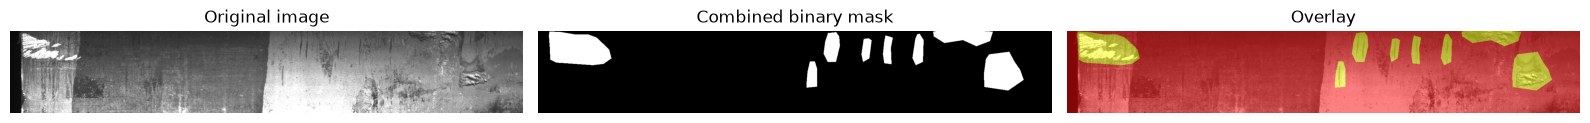

In [21]:
# RLE on single image first

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image

DATA_DIR = Path(r"E:\SAM\data")
IMAGE_DIR = DATA_DIR / "train_images"

df = pd.read_csv(DATA_DIR / "train.csv")

def decode_rle(encoded_pixels, height=256, width=1600):
    """Decode 1-indexed RLE into a binary mask using column-major order."""
    values = np.asarray(
        [int(v) for v in encoded_pixels.split()],
        dtype=np.int64
    )
    starts = values[0::2] - 1
    lengths = values[1::2]
    ends = starts + lengths

    flat_mask = np.zeros(height * width, dtype=np.uint8)

    for start, end in zip(starts, ends):
        if start < 0 or end > flat_mask.size or end < start:
            raise ValueError(f"Invalid RLE run: start={start}, end={end}")
        flat_mask[start:end] = 1

    return flat_mask.reshape((height, width), order="F")


image_id = "0025bde0c.jpg"
image_path = IMAGE_DIR / image_id

with Image.open(image_path) as img:
    image = np.array(img.convert("RGB"))

height, width = image.shape[:2]
rows = df[df["ImageId"] == image_id]

combined_mask = np.zeros((height, width), dtype=np.uint8)

print("Image:", image_id)
print("Image shape:", image.shape)
print("Classes present:", sorted(rows["ClassId"].unique().tolist()))

for _, row in rows.iterrows():
    class_mask = decode_rle(
        row["EncodedPixels"],
        height=height,
        width=width
    )
    print(
        f"Class {row['ClassId']}: "
        f"{int(class_mask.sum()):,} defect pixels"
    )
    combined_mask |= class_mask

print("Combined defect pixels:", int(combined_mask.sum()))
print("Mask shape:", combined_mask.shape)
print("Mask values:", np.unique(combined_mask))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].imshow(image)
axes[0].set_title("Original image")
axes[1].imshow(combined_mask, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Combined binary mask")
axes[2].imshow(image)
axes[2].imshow(combined_mask, cmap="autumn", alpha=0.5)
axes[2].set_title("Overlay")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()


In [22]:
# Multiple now

In [23]:

import numpy as np
import pandas as pd
from pathlib import Path
from PIL import Image

DATA_DIR = Path(r"E:\SAM\data")
IMAGE_DIR = DATA_DIR / "train_images"
df = pd.read_csv(DATA_DIR / "train.csv")

def decode_rle(encoded_pixels, height=256, width=1600):
    values = np.asarray(
        [int(v) for v in encoded_pixels.split()],
        dtype=np.int64
    )
    starts = values[0::2] - 1
    lengths = values[1::2]
    ends = starts + lengths

    flat_mask = np.zeros(height * width, dtype=np.uint8)

    for start, end in zip(starts, ends):
        if start < 0 or end > flat_mask.size or end <= start:
            raise ValueError(f"Invalid RLE run: {start}, {end}")
        flat_mask[start:end] = 1

    return flat_mask.reshape((height, width), order="F")


# Select examples with one class and multiple classes.
class_counts = df.groupby("ImageId")["ClassId"].nunique()
single_class_ids = sorted(class_counts[class_counts == 1].index)
multi_class_ids = sorted(class_counts[class_counts > 1].index)

test_ids = single_class_ids[:3] + multi_class_ids[:3]

print("Testing images:", test_ids)

for image_id in test_ids:
    with Image.open(IMAGE_DIR / image_id) as img:
        image = np.array(img.convert("RGB"))

    height, width = image.shape[:2]
    rows = df[df["ImageId"] == image_id]
    combined = np.zeros((height, width), dtype=np.uint8)

    for _, row in rows.iterrows():
        mask = decode_rle(
            row["EncodedPixels"],
            height=height,
            width=width
        )
        assert mask.shape == (height, width)
        assert set(np.unique(mask)).issubset({0, 1})
        combined |= mask

    assert combined.shape == (height, width)
    assert combined.sum() > 0

    print(
        f"PASS | {image_id} | "
        f"classes={sorted(rows['ClassId'].unique().tolist())} | "
        f"defect_pixels={int(combined.sum()):,}"
    )

print("\nAll selected decoder tests passed.")


Testing images: ['0002cc93b.jpg', '0007a71bf.jpg', '000a4bcdd.jpg', '0025bde0c.jpg', '002fc4e19.jpg', '008ef3d74.jpg']
PASS | 0002cc93b.jpg | classes=[1] | defect_pixels=4,396
PASS | 0007a71bf.jpg | classes=[3] | defect_pixels=6,897
PASS | 000a4bcdd.jpg | classes=[1] | defect_pixels=8,319
PASS | 0025bde0c.jpg | classes=[3, 4] | defect_pixels=46,047
PASS | 002fc4e19.jpg | classes=[1, 2] | defect_pixels=2,756
PASS | 008ef3d74.jpg | classes=[1, 2] | defect_pixels=5,276

All selected decoder tests passed.


In [24]:
# Verify the RLE decoder's round trip

import numpy as np
import pandas as pd
from pathlib import Path

DATA_DIR = Path(r"E:\SAM\data")
df = pd.read_csv(DATA_DIR / "train.csv")

def decode_rle(encoded_pixels, height=256, width=1600):
    values = np.asarray(
        [int(v) for v in encoded_pixels.split()],
        dtype=np.int64
    )
    starts = values[0::2] - 1
    lengths = values[1::2]
    ends = starts + lengths

    flat = np.zeros(height * width, dtype=np.uint8)
    for start, end in zip(starts, ends):
        if start < 0 or end > flat.size or end <= start:
            raise ValueError(f"Invalid RLE run: {start}, {end}")
        flat[start:end] = 1

    return flat.reshape((height, width), order="F")


def encode_rle(mask):
    # Flatten in the same column-major order as the dataset.
    pixels = mask.flatten(order="F")
    padded = np.concatenate(([0], pixels, [0]))
    changes = np.where(padded[1:] != padded[:-1])[0] + 1
    changes[1::2] -= changes[::2]
    return " ".join(map(str, changes))


test_rows = df.iloc[[0, 1, 3, 6, 9]]

for _, row in test_rows.iterrows():
    original_rle = row["EncodedPixels"]
    mask = decode_rle(original_rle)
    reconstructed_rle = encode_rle(mask)

    assert reconstructed_rle == original_rle, (
        f"Round-trip mismatch for {row['ImageId']}, "
        f"class {row['ClassId']}"
    )

    print(
        f"PASS | {row['ImageId']} | "
        f"class={row['ClassId']} | "
        f"pixels={int(mask.sum()):,}"
    )

print("\nAll round-trip tests passed.")


PASS | 0002cc93b.jpg | class=1 | pixels=4,396
PASS | 0007a71bf.jpg | class=3 | pixels=6,897
PASS | 000f6bf48.jpg | class=4 | pixels=69,357
PASS | 0025bde0c.jpg | class=4 | pixels=17,541
PASS | 002fc4e19.jpg | class=2 | pixels=1,209

All round-trip tests passed.


In [25]:

import pandas as pd
from pathlib import Path

DATA_DIR = Path(r"E:\SAM\data")

df = pd.read_csv(DATA_DIR / "train.csv")
image_dir = DATA_DIR / "train_images"

all_images = {
    p.name for p in image_dir.iterdir()
    if p.is_file() and p.suffix.lower() in {".jpg", ".jpeg", ".png"}
}
annotated_images = set(df["ImageId"].unique())
unannotated_images = sorted(all_images - annotated_images)

print("Total training images:", len(all_images))
print("Images with annotation rows:", len(annotated_images))
print("Images without annotation rows:", len(unannotated_images))
print("\nExamples of images without annotation rows:")
print(unannotated_images[:10])

# Verify that all CSV image IDs refer to available image files.
print(
    "\nAll CSV image IDs exist:",
    annotated_images.issubset(all_images)
)


Total training images: 12568
Images with annotation rows: 6666
Images without annotation rows: 5902

Examples of images without annotation rows:
['00031f466.jpg', '000418bfc.jpg', '000789191.jpg', '001982b08.jpg', '001d1b355.jpg', '001d3d093.jpg', '002e73b3c.jpg', '003ac9d2a.jpg', '005b92582.jpg', '005da33cf.jpg']

All CSV image IDs exist: True


In [26]:
#Create the dataset manifest

import hashlib
import json
import pandas as pd
from pathlib import Path

PROJECT_DIR = Path(r"E:\SAM")
DATA_DIR = PROJECT_DIR / "data"
MANIFEST_DIR = PROJECT_DIR / "manifests"
MANIFEST_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(DATA_DIR / "train.csv")
image_dir = DATA_DIR / "train_images"

all_images = sorted(
    p.name for p in image_dir.iterdir()
    if p.is_file() and p.suffix.lower() in {".jpg", ".jpeg", ".png"}
)
annotated_images = set(df["ImageId"].unique())

# Record the class IDs associated with each annotated image.
classes_by_image = (
    df.groupby("ImageId")["ClassId"]
    .apply(lambda values: sorted(int(v) for v in values.unique()))
    .to_dict()
)

records = []

for image_id in all_images:
    classes = classes_by_image.get(image_id, [])
    records.append({
        "ImageId": image_id,
        "has_annotation_rows": image_id in annotated_images,
        "class_ids": classes,
        "defect_free_candidate": image_id not in annotated_images,
    })

manifest_path = MANIFEST_DIR / "dataset_manifest.json"
with manifest_path.open("w", encoding="utf-8") as f:
    json.dump(records, f, indent=2)

# Hash the exact manifest bytes for reproducibility.
manifest_hash = hashlib.sha256(manifest_path.read_bytes()).hexdigest()

print("Manifest saved:", manifest_path)
print("Total records:", len(records))
print("Images with annotation rows:", sum(r["has_annotation_rows"] for r in records))
print("Defect-free candidates:", sum(r["defect_free_candidate"] for r in records))
print("Manifest SHA-256:", manifest_hash)
print("\nFirst 3 records:")
print(json.dumps(records[:3], indent=2))


Manifest saved: E:\SAM\manifests\dataset_manifest.json
Total records: 12568
Images with annotation rows: 6666
Defect-free candidates: 5902
Manifest SHA-256: 8395b172f2c3749b66e891b90bd52e6a24ead8119c86c69e8a5e156d28e21df4

First 3 records:
[
  {
    "ImageId": "0002cc93b.jpg",
    "has_annotation_rows": true,
    "class_ids": [
      1
    ],
    "defect_free_candidate": false
  },
  {
    "ImageId": "00031f466.jpg",
    "has_annotation_rows": false,
    "class_ids": [],
    "defect_free_candidate": true
  },
  {
    "ImageId": "000418bfc.jpg",
    "has_annotation_rows": false,
    "class_ids": [],
    "defect_free_candidate": true
  }
]


In [27]:

import hashlib
import json
from pathlib import Path

PROJECT_DIR = Path(r"E:\SAM")
MANIFEST_PATH = PROJECT_DIR / "manifests" / "dataset_manifest.json"

with MANIFEST_PATH.open("r", encoding="utf-8") as f:
    saved_records = json.load(f)

saved_hash = hashlib.sha256(
    MANIFEST_PATH.read_bytes()
).hexdigest()

image_ids = [record["ImageId"] for record in saved_records]

print("Manifest exists:", MANIFEST_PATH.exists())
print("Total records:", len(saved_records))
print("Unique image IDs:", len(set(image_ids)))
print("Has annotation rows:", sum(
    record["has_annotation_rows"] for record in saved_records
))
print("Defect-free candidates:", sum(
    record["defect_free_candidate"] for record in saved_records
))
print("SHA-256:", saved_hash)
print("IDs unique:", len(image_ids) == len(set(image_ids)))
print(
    "Counts add up:",
    sum(r["has_annotation_rows"] for r in saved_records)
    + sum(r["defect_free_candidate"] for r in saved_records)
    == len(saved_records)
)


Manifest exists: True
Total records: 12568
Unique image IDs: 12568
Has annotation rows: 6666
Defect-free candidates: 5902
SHA-256: 8395b172f2c3749b66e891b90bd52e6a24ead8119c86c69e8a5e156d28e21df4
IDs unique: True
Counts add up: True
